In [2]:
import re
import random
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd

In [3]:
SEED = 42

TOTAL_SENTENCES = 1_000_000
DEV_SIZE = 1_000
TEST_SIZE = 1_000

DATA_DIR = Path("indiccorp_hindi")
DATA_DIR.mkdir(exist_ok=True)

CORPUS_FILE = DATA_DIR / "hindi_1M_sentences.txt"

TRAIN_FILE = DATA_DIR / "train.txt"
DEV_FILE = DATA_DIR / "dev.txt"
TEST_FILE = DATA_DIR / "test.txt"

In [4]:
def sentence_tokenize_hindi(paragraph):
    """
    Convert one IndicCorp paragraph into individual Hindi sentences.
    """
    
    # Normalize whitespace
    paragraph = re.sub(r'\s+', ' ', paragraph).strip()
    
    if not paragraph:
        return []
    
    # Split after Hindi danda, question mark or exclamation mark
    sentences = re.split(
        r'(?<=[।!?])\s+',
        paragraph
    )
    
    sentences = [
        s.strip()
        for s in sentences
        if s.strip()
    ]
    
    return sentences

In [12]:
sample_paragraph = """
भारत एक विविधताओं से भरा हुआ देश है। 
यहाँ अनेक भाषाएँ और संस्कृतियाँ हैं। 
भारत की संस्कृति बहुत समृद्ध है!
"""

sentences = sentence_tokenize_hindi(sample_paragraph)

for i, sentence in enumerate(sentences, 1):
    print(i, sentence)

1 भारत एक विविधताओं से भरा हुआ देश है।
2 यहाँ अनेक भाषाएँ और संस्कृतियाँ हैं।
3 भारत की संस्कृति बहुत समृद्ध है!


In [5]:
!pip install -q datasets

In [6]:
from datasets import load_dataset
from pathlib import Path


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [7]:
DATASET_NAME = "ai4bharat/IndicCorpV2"
CONFIG_NAME = "indiccorp_v2"

TOTAL_SENTENCES = 1_000_000

DATA_DIR = Path("indiccorp_hindi")
DATA_DIR.mkdir(exist_ok=True)

CORPUS_FILE = DATA_DIR / "hindi_1M_sentences.txt"

In [8]:
dataset = load_dataset(
    DATASET_NAME,
    CONFIG_NAME,
    split="hin_Deva",
    streaming=True
)

print(dataset)

IterableDataset({
    features: Unknown,
    num_shards: 3
})


In [9]:
def sentence_tokenize_hindi(paragraph):
    """
    Convert a Hindi paragraph into individual sentences.
    """

    paragraph = re.sub(r'\s+', ' ', paragraph).strip()

    if not paragraph:
        return []

    sentences = re.split(
        r'(?<=[।!?])\s+',
        paragraph
    )

    return [
        sentence.strip()
        for sentence in sentences
        if sentence.strip()
    ]

In [16]:
for example in dataset.take(1):

    paragraph = example["text"]

    print("ORIGINAL PARAGRAPH:")
    print(paragraph[:1000])

    print("\n" + "=" * 80)

    print("TOKENIZED SENTENCES:")

    sentences = sentence_tokenize_hindi(paragraph)

    for i, sentence in enumerate(sentences[:10], 1):
        print(f"{i}. {sentence}")

ORIGINAL PARAGRAPH:
लोगों को बिलों संबंधी सुविधा देना ही उनका काम

TOKENIZED SENTENCES:
1. लोगों को बिलों संबंधी सुविधा देना ही उनका काम


In [21]:
def stream_hindi_sentences(
    dataset,
    output_file,
    target_sentences
):
    """
    Stream Hindi paragraphs from IndicCorpV2,
    sentence-tokenize them, and save exactly
    target_sentences to disk.
    """

    sentence_count = 0
    paragraph_count = 0

    with open(
        output_file,
        "w",
        encoding="utf-8"
    ) as f:

        for example in dataset:

            paragraph_count += 1

            paragraph = example["text"]

            if not paragraph:
                continue

            sentences = sentence_tokenize_hindi(
                paragraph
            )

            for sentence in sentences:

                if not sentence:
                    continue

                # One sentence per line
                f.write(sentence + "\n")

                sentence_count += 1

                if sentence_count % 100_000 == 0:
                    print(
                        f"Paragraphs streamed: "
                        f"{paragraph_count:,} | "
                        f"Sentences saved: "
                        f"{sentence_count:,}/{target_sentences:,}"
                    )

                if sentence_count >= target_sentences:
                    break

            if sentence_count >= target_sentences:
                break

    print("\nFinished streaming.")
    print("Paragraphs processed :", f"{paragraph_count:,}")
    print("Sentences saved      :", f"{sentence_count:,}")
    print("Saved to             :", output_file)

    return sentence_count

In [22]:
saved_count = stream_hindi_sentences(
    dataset,
    CORPUS_FILE,
    TOTAL_SENTENCES
)

Paragraphs streamed: 70,121 | Sentences saved: 100,000/1,000,000
Paragraphs streamed: 140,807 | Sentences saved: 200,000/1,000,000
Paragraphs streamed: 210,287 | Sentences saved: 300,000/1,000,000
Paragraphs streamed: 280,485 | Sentences saved: 400,000/1,000,000
Paragraphs streamed: 351,083 | Sentences saved: 500,000/1,000,000
Paragraphs streamed: 421,705 | Sentences saved: 600,000/1,000,000
Paragraphs streamed: 491,137 | Sentences saved: 700,000/1,000,000
Paragraphs streamed: 561,081 | Sentences saved: 800,000/1,000,000
Paragraphs streamed: 631,763 | Sentences saved: 900,000/1,000,000
Paragraphs streamed: 702,101 | Sentences saved: 1,000,000/1,000,000

Finished streaming.
Paragraphs processed : 702,101
Sentences saved      : 1,000,000
Saved to             : indiccorp_hindi/hindi_1M_sentences.txt


In [23]:
with open(
    CORPUS_FILE,
    "r",
    encoding="utf-8"
) as f:

    sentence_count = sum(
        1 for _ in f
    )

print("Total sentences:", sentence_count)

Total sentences: 1000000


In [24]:
with open(
    CORPUS_FILE,
    "r",
    encoding="utf-8"
) as f:

    for i in range(10):
        print(f"{i + 1}. {next(f).strip()}")

1. लोगों को बिलों संबंधी सुविधा देना ही उनका काम
2. इनेलो 1987 में उस वक्त ऐसे ही दोराहे पर खड़ी थी, जब पूर्व उपप्रधानमंत्री देवीलाल ने अपने पुत्र ओमप्रकाश चौटाला को अपना राजनीतिक उत्तराधिकारी घोषित किया था।
3. हालांकि तब पार्टी पर देवीलाल की मजबूत पकड़ के चलते पार्टी टूटने से बच गई थी।
4. 1989 में देवीलाल केन्द्र की राजनीति में सक्रिय हो गए थे और उनके उपप्रधानमंत्री बनने के पश्चात् उनके तीन बेटों जगदीश सिंह, रणजीत सिंह और ओमप्रकाश चौटाला में से रणजीत और ओमप्रकाश के बीच हरियाणा में उनकी राजनीतिक विरासत को लेकर जंग शुरू हो गई थी।
5. उन परिस्थितियों में देवीलाल ने कड़ा निर्णय लेते हुए पार्टी की बागडोर ओमप्रकाश चौटाला के हवाले कर दी थी, जिसके बाद रणजीत की बगावत का असर पार्टी, संगठन और उनकी सरकार पर भी पड़ा था।
6. उस समय रणजीत की नाराजगी के चलते उनके समर्थन में कई कैबिनेट मंत्रियों ने इस्तीफे दे दिए थे किन्तु तब पार्टी सुप्रीमो चौ. देवीलाल की हरियाणा की जनता पर इतनी मजबूत पकड़ थी कि ओमप्रकाश चौटाला को उत्तराधिकारी बनाने के उनके फैसले का जनता के बीच कोई खास विरोध नहीं हुआ था लेकिन आज स्थिति

In [25]:
def sentence_length(sentence):
    return len(sentence.split())


sentence_lengths = [
    sentence_length(sentence)
    for sentence in sentences
]

print("Minimum length:", min(sentence_lengths))
print("Maximum length:", max(sentence_lengths))
print("Average length:", sum(sentence_lengths) / len(sentence_lengths))

Minimum length: 9
Maximum length: 9
Average length: 9.0


In [26]:
def get_length_bucket(length):
    if length <= 5:
        return "1-5"
    elif length <= 10:
        return "6-10"
    elif length <= 15:
        return "11-15"
    elif length <= 20:
        return "16-20"
    elif length <= 30:
        return "21-30"
    elif length <= 40:
        return "31-40"
    elif length <= 50:
        return "41-50"
    else:
        return "51+"

In [27]:
from collections import defaultdict

buckets = defaultdict(list)

for idx, length in enumerate(sentence_lengths):
    bucket = get_length_bucket(length)
    buckets[bucket].append(idx)


for bucket, indices in buckets.items():
    print(f"{bucket:>6}: {len(indices):,}")

  6-10: 1


In [28]:
import random

random.seed(42)

DEV_SIZE = 1000
TEST_SIZE = 1000

dev_indices = []
test_indices = []

total_sentences = len(sentences)

for bucket, indices in buckets.items():

    indices = indices.copy()
    random.shuffle(indices)

    # Number of sentences from this bucket
    # proportional to its representation in corpus
    bucket_total = round(
        len(indices) / total_sentences
        * (DEV_SIZE + TEST_SIZE)
    )

    selected = indices[:bucket_total]

    # Half for dev, half for test
    dev_count = bucket_total // 2

    dev_indices.extend(
        selected[:dev_count]
    )

    test_indices.extend(
        selected[dev_count:]
    )

print("Initial DEV:", len(dev_indices))
print("Initial TEST:", len(test_indices))

Initial DEV: 1
Initial TEST: 0


In [29]:
# Shuffle selected indices
random.shuffle(dev_indices)
random.shuffle(test_indices)

# Keep exactly the required number
dev_indices = dev_indices[:DEV_SIZE]
test_indices = test_indices[:TEST_SIZE]

# Make sure there is no overlap
dev_indices = set(dev_indices)
test_indices = set(test_indices)

print("DEV :", len(dev_indices))
print("TEST:", len(test_indices))
print(
    "Overlap:",
    len(dev_indices & test_indices)
)

DEV : 998
TEST: 1000
Overlap: 0


In [30]:
train_sentences = []
dev_sentences = []
test_sentences = []

for idx, sentence in enumerate(sentences):

    if idx in dev_indices:
        dev_sentences.append(sentence)

    elif idx in test_indices:
        test_sentences.append(sentence)

    else:
        train_sentences.append(sentence)


print("TRAIN:", len(train_sentences))
print("DEV  :", len(dev_sentences))
print("TEST :", len(test_sentences))

TRAIN: 998002
DEV  : 998
TEST : 1000


In [31]:
print(
    "Total:",
    len(train_sentences)
    + len(dev_sentences)
    + len(test_sentences)
)

Total: 1000000


In [32]:
DATA_DIR = Path("indiccorp_hindi")

TRAIN_FILE = DATA_DIR / "train.txt"
DEV_FILE = DATA_DIR / "dev.txt"
TEST_FILE = DATA_DIR / "test.txt"


def save_sentences(sentences, path):

    with open(path, "w", encoding="utf-8") as f:
        for sentence in sentences:
            f.write(sentence + "\n")


save_sentences(train_sentences, TRAIN_FILE)
save_sentences(dev_sentences, DEV_FILE)
save_sentences(test_sentences, TEST_FILE)

print("Saved successfully!")
print(TRAIN_FILE)
print(DEV_FILE)
print(TEST_FILE)

Saved successfully!
indiccorp_hindi/train.txt
indiccorp_hindi/dev.txt
indiccorp_hindi/test.txt


In [33]:
from pathlib import Path

DATA_DIR = Path("indiccorp_hindi")

TRAIN_FILE = DATA_DIR / "train.txt"
DEV_FILE = DATA_DIR / "dev.txt"
TEST_FILE = DATA_DIR / "test.txt"


def load_sentences(file_path):
    with open(file_path, "r", encoding="utf-8") as f:
        return [line.strip() for line in f if line.strip()]


train_sentences = load_sentences(TRAIN_FILE)
dev_sentences = load_sentences(DEV_FILE)
test_sentences = load_sentences(TEST_FILE)

print("Train:", len(train_sentences))
print("Dev  :", len(dev_sentences))
print("Test :", len(test_sentences))

Train: 998002
Dev  : 998
Test : 1000


In [34]:
START = "<START>"
END = "<END>"
UNK = "<UNK>"
def tokenize(sentence):
    """
    Tokenize a Hindi sentence into words and punctuation.
    """

    tokens = re.findall(
        r'[\u0900-\u097F]+|[.,!?;:()"\']',
        sentence
    )

    return tokens

In [35]:
sample = dev_sentences[0]

print(sample)
print(tokenize(sample))

अशुद्ध जगहों पर स्वास्तिक बनाना निषेध माना जाता है।
['अशुद्ध', 'जगहों', 'पर', 'स्वास्तिक', 'बनाना', 'निषेध', 'माना', 'जाता', 'है।']


In [36]:
word_counts = Counter()

for sentence in train_sentences:
    tokens = tokenize(sentence)
    word_counts.update(tokens)

vocab = set(word_counts.keys())

# Add special token
vocab.add(START)
vocab.add(END)
vocab.add(UNK)

V = len(vocab)

print("Vocabulary size:", V)
print("Most common words:")
print(word_counts.most_common(20))

Vocabulary size: 281971
Most common words:
[('के', 836316), ('में', 640724), ('की', 506857), (',', 453542), ('को', 392376), ('से', 371659), ('ने', 285261), ('का', 277374), ('और', 267585), ('.', 267522), ('है।', 267481), ('है', 263419), ('पर', 235369), ('कि', 190919), ('भी', 159759), ('लिए', 131526), ('एक', 122594), ('कर', 117074), ('इस', 116881), ('नहीं', 110072)]


In [37]:
def replace_unknowns(tokens, vocab):
    return [
        token if token in vocab else UNK
        for token in tokens
    ]

In [38]:
def generate_ngrams(tokens, n):
    """
    Generate n-grams from a token sequence.
    """

    return [
        tuple(tokens[i:i+n])
        for i in range(len(tokens) - n + 1)
    ]

In [39]:
def build_ngram_model(sentences, n, vocab):

    ngram_counts = Counter()
    context_counts = Counter()

    for sentence in sentences:

        tokens = tokenize(sentence)

        tokens = replace_unknowns(
            tokens,
            vocab
        )

        # Add sentence boundaries
        tokens = (
            [START] * (n - 1)
            + tokens
            + [END]
        )

        ngrams = generate_ngrams(
            tokens,
            n
        )

        for ngram in ngrams:

            ngram_counts[ngram] += 1

            if n > 1:
                context = ngram[:-1]
                context_counts[context] += 1

    return ngram_counts, context_counts

In [40]:
models = {}

for n in range(1, 5):

    ngram_counts, context_counts = build_ngram_model(
        train_sentences,
        n,
        vocab
    )

    models[n] = {
        "ngram_counts": ngram_counts,
        "context_counts": context_counts
    }

    print(
        f"N={n}: "
        f"{len(ngram_counts):,} unique n-grams"
    )

N=1: 281,969 unique n-grams
N=2: 3,537,238 unique n-grams
N=3: 10,361,460 unique n-grams
N=4: 15,537,229 unique n-grams


In [41]:
def unsmoothed_probability(ngram, model):

    n = len(ngram)

    count = model["ngram_counts"].get(
        ngram,
        0
    )

    # Unigram
    if n == 1:

        total = sum(
            model["ngram_counts"].values()
        )

        if total == 0:
            return 0.0

        return count / total

    # N > 1
    context = ngram[:-1]

    context_count = model["context_counts"].get(
        context,
        0
    )

    if context_count == 0:
        return 0.0

    return count / context_count

In [42]:
bigram_model = models[2]

example = ("यह", "एक")

print(
    "Count:",
    bigram_model["ngram_counts"].get(example, 0)
)

print(
    "Probability:",
    unsmoothed_probability(
        example,
        bigram_model
    )
)

Count: 1548
Probability: 0.0223990739400955


In [43]:
def add_one_probability(ngram, model, vocab_size):
    """
    Calculate Add-1 (Laplace) smoothed probability.
    """

    n = len(ngram)

    count = model["ngram_counts"].get(
        ngram,
        0
    )

    # Unigram
    if n == 1:

        total_count = sum(
            model["ngram_counts"].values()
        )

        return (
            count + 1
        ) / (
            total_count + vocab_size
        )

    # Bigram / Trigram / Quadram
    context = ngram[:-1]

    context_count = model["context_counts"].get(
        context,
        0
    )

    return (
        count + 1
    ) / (
        context_count + vocab_size
    )

In [44]:
bigram_model = models[2]

existing_bigram = ("यह", "एक")

print(
    "Existing bigram:",
    existing_bigram
)

print(
    "Count:",
    bigram_model["ngram_counts"].get(
        existing_bigram,
        0
    )
)

print(
    "Add-1 probability:",
    add_one_probability(
        existing_bigram,
        bigram_model,
        V
    )
)

Existing bigram: ('यह', 'एक')
Count: 1548
Add-1 probability: 0.004412087239127153


In [45]:
unseen_bigram = (
    "यह",
    "xyz"
)

print(
    "Unseen bigram probability:",
    add_one_probability(
        unseen_bigram,
        bigram_model,
        V
    )
)

Unseen bigram probability: 2.8483455384939656e-06


In [46]:
def add_k_probability(
    ngram,
    model,
    vocab_size,
    k=0.5
):
    """
    Calculate Add-K smoothed probability.
    """

    n = len(ngram)

    count = model["ngram_counts"].get(
        ngram,
        0
    )

    # Unigram
    if n == 1:

        total_count = sum(
            model["ngram_counts"].values()
        )

        return (
            count + k
        ) / (
            total_count + k * vocab_size
        )

    # Higher-order N-gram
    context = ngram[:-1]

    context_count = model["context_counts"].get(
        context,
        0
    )

    return (
        count + k
    ) / (
        context_count + k * vocab_size
    )

In [49]:
K = 0.5
print(
    "Add-K probability:",
    add_k_probability(
        existing_bigram,
        bigram_model,
        V,
        K
    )
)

Add-K probability: 0.007370457720417619


In [50]:
print(
    "Unseen bigram Add-K probability:",
    add_k_probability(
        unseen_bigram,
        bigram_model,
        V,
        K
    )
)

Unseen bigram Add-K probability: 2.3798701066895768e-06


In [52]:
def get_interpolation_weights(n):
    """
    Return equal interpolation weights
    for orders 1 through n.
    """

    return [
        1.0 / n
        for _ in range(n)
    ]
print("Bigram:", get_interpolation_weights(2))
print("Trigram:", get_interpolation_weights(3))
print("Quadram:", get_interpolation_weights(4))

Bigram: [0.5, 0.5]
Trigram: [0.3333333333333333, 0.3333333333333333, 0.3333333333333333]
Quadram: [0.25, 0.25, 0.25, 0.25]


In [53]:
def interpolated_probability(
    ngram,
    models
):
    """
    Calculate interpolated N-gram probability
    using all lower-order models.
    """

    n = len(ngram)

    # Unigram does not need interpolation
    if n == 1:
        return unsmoothed_probability(
            ngram,
            models[1]
        )

    lambdas = get_interpolation_weights(n)

    probability = 0.0

    for order in range(1, n + 1):

        # Take the last `order` tokens
        lower_order_ngram = ngram[-order:]

        lower_model = models[order]

        p = unsmoothed_probability(
            lower_order_ngram,
            lower_model
        )

        probability += (
            lambdas[order - 1] * p
        )

    return probability

In [54]:
def build_kneser_ney_statistics(
    train_sentences,
    vocab
):
    """
    Build statistics required for Kneser-Ney smoothing.
    """

    bigram_types = set()

    for sentence in train_sentences:

        tokens = tokenize(sentence)

        tokens = replace_unknowns(
            tokens,
            vocab
        )

        tokens = (
            [START]
            + tokens
            + [END]
        )

        bigrams = generate_ngrams(
            tokens,
            2
        )

        for bigram in bigrams:
            bigram_types.add(bigram)

    # Number of unique preceding words
    # for each word
    continuation_counts = Counter()

    for previous_word, word in bigram_types:

        continuation_counts[word] += 1

    total_unique_bigrams = len(
        bigram_types
    )

    return (
        continuation_counts,
        total_unique_bigrams
    )

In [55]:
continuation_counts, total_unique_bigrams = (
    build_kneser_ney_statistics(
        train_sentences,
        vocab
    )
)

print(
    "Unique bigram types:",
    total_unique_bigrams
)

print(
    "Example continuation counts:"
)

print(
    continuation_counts.most_common(20)
)

Unique bigram types: 3537238
Example continuation counts:
[('के', 53425), (',', 48353), ('की', 37380), ('में', 35113), ('और', 32046), ('को', 31189), ('का', 29116), ('<END>', 27153), ('से', 27115), ('ने', 26692), ('पर', 15939), ('(', 14572), ('भी', 13315), ('व', 12098), ('है', 10494), (')', 10321), ('.', 9914), ('नहीं', 9809), ('है।', 8687), ("'", 7559)]


In [56]:
D = 0.75


def kneser_ney_unigram(word):
    """
    Kneser-Ney continuation probability.
    """

    if total_unique_bigrams == 0:
        return 0.0

    return (
        continuation_counts.get(
            word,
            0
        )
        / total_unique_bigrams
    )

In [57]:
def kneser_ney_bigram_probability(
    ngram,
    model,
    d=0.75
):
    """
    Kneser-Ney probability for a bigram.
    """

    previous_word, word = ngram

    bigram_count = model["ngram_counts"].get(
        ngram,
        0
    )

    context_count = model["context_counts"].get(
        (previous_word,),
        0
    )

    # If context was never seen,
    # fall back to continuation probability
    if context_count == 0:
        return kneser_ney_unigram(word)

    # Number of unique words following
    # the previous word
    unique_following = sum(
        1
        for bg in model["ngram_counts"]
        if bg[0] == previous_word
    )

    lambda_value = (
        d * unique_following
    ) / context_count

    discounted_probability = (
        max(bigram_count - d, 0)
        / context_count
    )

    continuation_probability = (
        kneser_ney_unigram(word)
    )

    return (
        discounted_probability
        +
        lambda_value
        * continuation_probability
    )

In [58]:
def kneser_ney_probability(
    ngram,
    models,
    d=0.75
):
    """
    General Kneser-Ney probability for
    unigram, bigram, trigram and quadram.
    """

    n = len(ngram)

    # -------------------------
    # Unigram
    # -------------------------

    if n == 1:

        return kneser_ney_unigram(
            ngram[0]
        )

    model = models[n]

    count = model["ngram_counts"].get(
        ngram,
        0
    )

    context = ngram[:-1]

    context_count = model["context_counts"].get(
        context,
        0
    )

    # If context does not exist,
    # recursively use lower-order model
    if context_count == 0:

        return kneser_ney_probability(
            ngram[1:],
            models,
            d
        )

    # Number of unique continuation types
    unique_continuations = sum(
        1
        for ng in model["ngram_counts"]
        if ng[:-1] == context
    )

    lambda_value = (
        d * unique_continuations
    ) / context_count

    discounted_probability = (
        max(count - d, 0)
        / context_count
    )

    lower_order_probability = (
        kneser_ney_probability(
            ngram[1:],
            models,
            d
        )
    )

    return (
        discounted_probability
        +
        lambda_value
        * lower_order_probability
    )

In [59]:
example_bigram = (
    "यह",
    "एक"
)

print(
    "Kneser-Ney bigram probability:",
    kneser_ney_probability(
        example_bigram,
        models,
        D
    )
)

Kneser-Ney bigram probability: 0.022562424586648127


In [60]:
example_trigram = (
    "यह",
    "एक",
    "अच्छा"
)

print(
    "Kneser-Ney trigram probability:",
    kneser_ney_probability(
        example_trigram,
        models,
        D
    )
)

Kneser-Ney trigram probability: 0.02328739785500058


In [61]:
def get_probability(
    ngram,
    method,
    models,
    vocab_size,
    k=0.5,
    d=0.75
):
    """
    Return the probability of an n-gram
    using the selected smoothing method.
    """

    n = len(ngram)

    if method == "unsmoothed":

        return unsmoothed_probability(
            ngram,
            models[n]
        )

    elif method == "add_one":

        return add_one_probability(
            ngram,
            models[n],
            vocab_size
        )

    elif method == "add_k":

        return add_k_probability(
            ngram,
            models[n],
            vocab_size,
            k
        )

    elif method == "interpolated":

        return interpolated_probability(
            ngram,
            models
        )

    elif method == "kneser_ney":

        return kneser_ney_probability(
            ngram,
            models,
            d
        )

    else:

        raise ValueError(
            f"Unknown smoothing method: {method}"
        )

In [62]:
def sentence_log_probability(
    sentence,
    n,
    method,
    models,
    vocab,
    vocab_size,
    k=0.5,
    d=0.75
):
    """
    Calculate the log probability of a sentence.
    """

    # Tokenize
    tokens = tokenize(sentence)

    # Replace unseen words
    tokens = replace_unknowns(
        tokens,
        vocab
    )

    # Add sentence boundaries
    tokens = (
        [START] * (n - 1)
        + tokens
        + [END]
    )

    # Generate n-grams
    ngrams = generate_ngrams(
        tokens,
        n
    )

    log_probability = 0.0

    for ngram in ngrams:

        probability = get_probability(
            ngram,
            method,
            models,
            vocab_size,
            k,
            d
        )

        # Zero probability means
        # sentence probability is zero
        if probability <= 0:

            return float("-inf")

        log_probability += math.log(
            probability
        )

    return log_probability

In [63]:
import math

In [64]:
def calculate_perplexity(
    sentences,
    n,
    method,
    models,
    vocab,
    vocab_size,
    k=0.5,
    d=0.75
):
    """
    Calculate perplexity over a collection of sentences.
    """

    total_log_probability = 0.0
    total_tokens = 0

    for sentence in sentences:

        # Count actual tokens + END
        tokens = tokenize(sentence)

        tokens = replace_unknowns(
            tokens,
            vocab
        )

        total_tokens += len(tokens) + 1

        log_probability = sentence_log_probability(
            sentence,
            n,
            method,
            models,
            vocab,
            vocab_size,
            k,
            d
        )

        # If any sentence has zero probability,
        # perplexity becomes infinite.
        if log_probability == float("-inf"):

            return float("inf")

        total_log_probability += (
            log_probability
        )

    if total_tokens == 0:
        return float("inf")

    perplexity = math.exp(
        -total_log_probability
        / total_tokens
    )

    return perplexity

In [65]:
test_pp = calculate_perplexity(
    dev_sentences[:100],
    n=2,
    method="add_one",
    models=models,
    vocab=vocab,
    vocab_size=V
)

print(
    "Bigram Add-1 Perplexity:",
    test_pp
)

Bigram Add-1 Perplexity: 3714.595085794923


In [66]:
methods = [
    "unsmoothed",
    "add_one",
    "add_k",
    "interpolated",
    "kneser_ney"
]

for method in methods:

    pp = calculate_perplexity(
        dev_sentences[:100],
        n=2,
        method=method,
        models=models,
        vocab=vocab,
        vocab_size=V,
        k=0.5,
        d=0.75
    )

    print(
        f"{method:15s} : {pp}"
    )

unsmoothed      : inf
add_one         : 3714.595085794923
add_k           : 2470.6235281472536
interpolated    : inf
kneser_ney      : inf


In [67]:
results = []

for n in range(1, 5):

    print(
        f"\n========== N = {n} =========="
    )

    for method in methods:

        print(
            f"Running {method}..."
        )

        perplexity = calculate_perplexity(
            dev_sentences,
            n=n,
            method=method,
            models=models,
            vocab=vocab,
            vocab_size=V,
            k=0.5,
            d=0.75
        )

        results.append({
            "N": n,
            "Model": method,
            "Perplexity": perplexity
        })

        print(
            f"Perplexity: {perplexity}"
        )


========== N = 1 ==========
Running unsmoothed...
Perplexity: inf
Running add_one...
Perplexity: 1668.7052819436178
Running add_k...
Perplexity: 1672.9869816404234
Running interpolated...
Perplexity: inf
Running kneser_ney...
Perplexity: inf

========== N = 2 ==========
Running unsmoothed...
Perplexity: inf
Running add_one...
Perplexity: 3652.5981475715266
Running add_k...
Perplexity: 2423.598903848527
Running interpolated...
Perplexity: inf
Running kneser_ney...
Perplexity: inf

========== N = 3 ==========
Running unsmoothed...
Perplexity: inf
Running add_one...
Perplexity: 38424.59132185887
Running add_k...
Perplexity: 27523.656826394934
Running interpolated...
Perplexity: inf
Running kneser_ney...
Perplexity: inf

========== N = 4 ==========
Running unsmoothed...
Perplexity: inf
Running add_one...
Perplexity: 111992.11781455859
Running add_k...
Perplexity: 94368.72934350718
Running interpolated...
Perplexity: inf
Running kneser_ney...


KeyboardInterrupt: 

In [68]:
print("UNK in vocabulary:", UNK in vocab)
print("UNK unigram count:", models[1]["ngram_counts"].get((UNK,), 0))

UNK in vocabulary: True
UNK unigram count: 0


In [69]:
# Build vocabulary from training data
word_counts = Counter()

for sentence in train_sentences:
    tokens = tokenize(sentence)
    word_counts.update(tokens)

# Keep all observed training words
vocab = set(word_counts.keys())

# Add special tokens
vocab.update({
    START,
    END,
    UNK
})

V = len(vocab)

print("Vocabulary size:", V)

Vocabulary size: 281971


In [71]:
def build_ngram_model(sentences, n, vocab):
    
    ngram_counts = Counter()
    context_counts = Counter()

    for sentence in sentences:

        tokens = tokenize(sentence)

        # Replace words outside vocabulary with UNK
        tokens = [
            token if token in vocab else UNK
            for token in tokens
        ]

        # Add sentence boundaries
        tokens = (
            [START] * (n - 1)
            + tokens
            + [END]
        )

        ngrams = generate_ngrams(
            tokens,
            n
        )

        for ngram in ngrams:

            ngram_counts[ngram] += 1

            if n > 1:
                context_counts[ngram[:-1]] += 1

    return ngram_counts, context_counts

In [72]:
# Give UNK a small non-zero training count
# so unseen evaluation words have non-zero probability.

for n in range(1, 5):
    
    models[n]["ngram_counts"][
        (UNK,) if n == 1 else tuple([START] * (n - 1) + [UNK])
    ] += 1

In [73]:
from collections import defaultdict


def build_kn_statistics(models):
    
    kn_stats = {}
    
    # ------------------------------------------------
    # Bigram statistics
    # ------------------------------------------------
    
    bigram_counts = models[2]["ngram_counts"]
    
    # For each word:
    # number of unique preceding words
    continuation_counts = Counter()
    
    # For each previous word:
    # number of unique following words
    unique_following = Counter()
    
    for previous_word, word in bigram_counts.keys():
        
        continuation_counts[word] += 1
        unique_following[previous_word] += 1
    
    total_unique_bigrams = len(
        bigram_counts
    )
    
    kn_stats[1] = {
        "continuation_counts": continuation_counts,
        "total_unique_bigrams": total_unique_bigrams
    }
    
    # ------------------------------------------------
    # Higher-order statistics
    # ------------------------------------------------
    
    for n in range(2, 5):
        
        ngram_counts = models[n]["ngram_counts"]
        
        unique_continuations = Counter()
        
        for ngram in ngram_counts.keys():
            
            context = ngram[:-1]
            
            unique_continuations[context] += 1
        
        kn_stats[n] = {
            "unique_continuations": unique_continuations
        }
    
    return kn_stats

In [74]:
kn_stats = build_kn_statistics(models)

print(
    "Unique bigrams:",
    kn_stats[1]["total_unique_bigrams"]
)

Unique bigrams: 3537239


In [75]:
def kn_unigram_probability(
    word,
    kn_stats
):
    
    continuation_counts = (
        kn_stats[1]["continuation_counts"]
    )
    
    total = (
        kn_stats[1]["total_unique_bigrams"]
    )
    
    if total == 0:
        return 0.0
    
    count = continuation_counts.get(
        word,
        0
    )
    
    # Fallback for UNK
    if count == 0 and word == UNK:
        return 1.0 / total
    
    return count / total

In [76]:
D = 0.75


def kneser_ney_probability(
    ngram,
    models,
    kn_stats,
    d=0.75
):
    
    n = len(ngram)
    
    # -----------------------------------------
    # Unigram
    # -----------------------------------------
    
    if n == 1:
        
        return kn_unigram_probability(
            ngram[0],
            kn_stats
        )
    
    model = models[n]
    
    count = model["ngram_counts"].get(
        ngram,
        0
    )
    
    context = ngram[:-1]
    
    context_count = model["context_counts"].get(
        context,
        0
    )
    
    # -----------------------------------------
    # Unseen context
    # -----------------------------------------
    
    if context_count == 0:
        
        return kneser_ney_probability(
            ngram[1:],
            models,
            kn_stats,
            d
        )
    
    # -----------------------------------------
    # Number of unique continuations
    # -----------------------------------------
    
    unique_continuations = (
        kn_stats[n]["unique_continuations"]
        .get(context, 0)
    )
    
    # Backoff weight
    lambda_value = (
        d * unique_continuations
        / context_count
    )
    
    # Discounted probability
    first_term = (
        max(count - d, 0)
        / context_count
    )
    
    # Lower-order probability
    lower_probability = (
        kneser_ney_probability(
            ngram[1:],
            models,
            kn_stats,
            d
        )
    )
    
    return (
        first_term
        +
        lambda_value * lower_probability
    )

In [77]:
kn_stats = build_kn_statistics(models)

print("Kneser-Ney statistics ready.")

Kneser-Ney statistics ready.


In [78]:
example_bigram = (
    "यह",
    "एक"
)

print(
    kneser_ney_probability(
        example_bigram,
        models,
        kn_stats,
        D
    )
)

0.022562424537399855


In [79]:
example_trigram = (
    "यह",
    "एक",
    "अच्छा"
)

print(
    kneser_ney_probability(
        example_trigram,
        models,
        kn_stats,
        D
    )
)

0.023287397853533925


In [80]:
def interpolated_probability(
    ngram,
    models,
    vocab_size
):
    
    n = len(ngram)
    
    if n == 1:
        return add_one_probability(
            ngram,
            models[1],
            vocab_size
        )
    
    lambdas = [
        1.0 / n
        for _ in range(n)
    ]
    
    probability = 0.0
    
    for order in range(1, n + 1):
        
        lower_ngram = ngram[-order:]
        
        p = add_one_probability(
            lower_ngram,
            models[order],
            vocab_size
        )
        
        probability += (
            lambdas[order - 1] * p
        )
    
    return probability

In [81]:
def get_probability(
    ngram,
    method,
    models,
    vocab_size,
    kn_stats,
    k=0.5,
    d=0.75
):
    
    n = len(ngram)

    if method == "unsmoothed":

        return unsmoothed_probability(
            ngram,
            models[n]
        )

    elif method == "add_one":

        return add_one_probability(
            ngram,
            models[n],
            vocab_size
        )

    elif method == "add_k":

        return add_k_probability(
            ngram,
            models[n],
            vocab_size,
            k
        )

    elif method == "interpolated":

        return interpolated_probability(
            ngram,
            models,
            vocab_size
        )

    elif method == "kneser_ney":

        return kneser_ney_probability(
            ngram,
            models,
            kn_stats,
            d
        )

    else:

        raise ValueError(
            f"Unknown method: {method}"
        )

In [82]:
def sentence_log_probability(
    sentence,
    n,
    method,
    models,
    vocab,
    vocab_size,
    kn_stats,
    k=0.5,
    d=0.75
):

    tokens = tokenize(sentence)

    tokens = replace_unknowns(
        tokens,
        vocab
    )

    tokens = (
        [START] * (n - 1)
        + tokens
        + [END]
    )

    ngrams = generate_ngrams(
        tokens,
        n
    )

    log_probability = 0.0

    for ngram in ngrams:

        probability = get_probability(
            ngram,
            method,
            models,
            vocab_size,
            kn_stats,
            k,
            d
        )

        if probability <= 0:

            return float("-inf")

        log_probability += math.log(
            probability
        )

    return log_probability

In [83]:
def calculate_perplexity(
    sentences,
    n,
    method,
    models,
    vocab,
    vocab_size,
    kn_stats,
    k=0.5,
    d=0.75
):

    total_log_probability = 0.0
    total_tokens = 0

    for sentence in sentences:

        tokens = tokenize(sentence)

        tokens = replace_unknowns(
            tokens,
            vocab
        )

        total_tokens += len(tokens) + 1

        log_probability = sentence_log_probability(
            sentence,
            n,
            method,
            models,
            vocab,
            vocab_size,
            kn_stats,
            k,
            d
        )

        if log_probability == float("-inf"):

            return float("inf")

        total_log_probability += (
            log_probability
        )

    return math.exp(
        -total_log_probability
        / total_tokens
    )

In [84]:
kn_test = calculate_perplexity(
    dev_sentences[:100],
    n=3,
    method="kneser_ney",
    models=models,
    vocab=vocab,
    vocab_size=V,
    kn_stats=kn_stats,
    d=0.75
)

print(
    "Trigram Kneser-Ney PP:",
    kn_test
)

Trigram Kneser-Ney PP: 186.56681598546191


In [85]:
interp_test = calculate_perplexity(
    dev_sentences[:100],
    n=3,
    method="interpolated",
    models=models,
    vocab=vocab,
    vocab_size=V,
    kn_stats=kn_stats
)

print(
    "Trigram Interpolated PP:",
    interp_test
)

Trigram Interpolated PP: 1809.2019817287721


In [86]:
# Check some Kneser-Ney probabilities

test_ngrams = [
    ("यह",),
    ("यह", "एक"),
    ("यह", "एक", "अच्छा"),
]

for ngram in test_ngrams:
    p = kneser_ney_probability(
        ngram,
        models,
        kn_stats,
        d=0.75
    )

    print(
        f"{ngram} -> {p:.10f}"
    )

('यह',) -> 0.0006527690
('यह', 'एक') -> 0.0225624245
('यह', 'एक', 'अच्छा') -> 0.0232873979


In [87]:
methods = [
    "unsmoothed",
    "add_one",
    "add_k",
    "interpolated",
    "kneser_ney"
]

results = []

for n in range(1, 5):

    print(f"\n{'=' * 50}")
    print(f"N-GRAM ORDER: {n}")
    print(f"{'=' * 50}")

    for method in methods:

        print(f"Running {method}...")

        perplexity = calculate_perplexity(
            dev_sentences,
            n=n,
            method=method,
            models=models,
            vocab=vocab,
            vocab_size=V,
            kn_stats=kn_stats,
            k=0.5,
            d=0.75
        )

        results.append({
            "N": n,
            "Method": method,
            "Perplexity": perplexity
        })

        print(
            f"{method:15s} -> "
            f"{perplexity:.4f}"
        )


N-GRAM ORDER: 1
Running unsmoothed...
unsmoothed      -> 1659.5473
Running add_one...
add_one         -> 1659.3621
Running add_k...
add_k           -> 1658.1646
Running interpolated...
interpolated    -> 1659.3621
Running kneser_ney...
kneser_ney      -> 2596.4613

N-GRAM ORDER: 2
Running unsmoothed...
unsmoothed      -> inf
Running add_one...
add_one         -> 3650.8507
Running add_k...
add_k           -> 2421.7614
Running interpolated...
interpolated    -> 1344.3717
Running kneser_ney...
kneser_ney      -> 246.8181

N-GRAM ORDER: 3
Running unsmoothed...
unsmoothed      -> inf
Running add_one...
add_one         -> 38406.2081
Running add_k...
add_k           -> 27502.7890
Running interpolated...
interpolated    -> 1791.2369
Running kneser_ney...
kneser_ney      -> 181.1526

N-GRAM ORDER: 4
Running unsmoothed...
unsmoothed      -> inf
Running add_one...
add_one         -> 111938.5381
Running add_k...
add_k           -> 94297.1810
Running interpolated...
interpolated    -> 2253.7252
Ru

In [88]:
results_df = pd.DataFrame(results)

results_df

,N,Method,Perplexity
0,1,unsmoothed,1.659547e+03
1,1,add_one,1.659362e+03
2,1,add_k,1.658165e+03
3,1,interpolated,1.659362e+03
4,1,kneser_ney,2.596461e+03
5,2,unsmoothed,inf
6,2,add_one,3.650851e+03
7,2,add_k,2.421761e+03
8,2,interpolated,1.344372e+03
9,2,kneser_ney,2.468181e+02


In [89]:
comparison = results_df.pivot(
    index="Method",
    columns="N",
    values="Perplexity"
)

comparison.columns = [
    "Unigram",
    "Bigram",
    "Trigram",
    "Quadram"
]

comparison

,Unigram,Bigram,Trigram,Quadram
Method,,,,
add_k,1658.164645,2421.761384,2.750279e+04,9.429718e+04
add_one,1659.362078,3650.850657,3.840621e+04,1.119385e+05
interpolated,1659.362078,1344.371694,1.791237e+03,2.253725e+03
kneser_ney,2596.461348,246.818141,1.811526e+02,1.878745e+02
unsmoothed,1659.547262,inf,inf,inf


In [90]:
valid_results = results_df[
    np.isfinite(
        results_df["Perplexity"]
    )
]

best = valid_results.loc[
    valid_results["Perplexity"].idxmin()
]

print("Best model:")
print(best)

Best model:
N                      3
Method        kneser_ney
Perplexity    181.152598
Name: 14, dtype: object


In [91]:
best_per_n = (
    results_df[
        np.isfinite(results_df["Perplexity"])
    ]
    .loc[
        lambda df: df.groupby("N")["Perplexity"].idxmin()
    ]
    .sort_values("N")
    .reset_index(drop=True)
)

best_per_n

,N,Method,Perplexity
0,1,add_k,1658.164645
1,2,kneser_ney,246.818141
2,3,kneser_ney,181.152598
3,4,kneser_ney,187.874548


In [92]:
for _, row in best_per_n.iterrows():
    print(
        f"N={int(row['N'])}: "
        f"{row['Method']} "
        f"(Perplexity = {row['Perplexity']:.2f})"
    )

N=1: add_k (Perplexity = 1658.16)
N=2: kneser_ney (Perplexity = 246.82)
N=3: kneser_ney (Perplexity = 181.15)
N=4: kneser_ney (Perplexity = 187.87)


In [93]:
add_one_df = (
    results_df[results_df["Method"] == "add_one"]
    [["N", "Perplexity"]]
    .rename(columns={"Perplexity": "Add_1"})
)

kn_df = (
    results_df[results_df["Method"] == "kneser_ney"]
    [["N", "Perplexity"]]
    .rename(columns={"Perplexity": "Kneser_Ney"})
)

kn_comparison = add_one_df.merge(kn_df, on="N")

kn_comparison["Improvement_%"] = (
    (kn_comparison["Add_1"] - kn_comparison["Kneser_Ney"])
    / kn_comparison["Add_1"]
    * 100
)

kn_comparison

,N,Add_1,Kneser_Ney,Improvement_%
0,1,1659.362078,2596.461348,-56.473465
1,2,3650.850657,246.818141,93.239435
2,3,38406.208071,181.152598,99.528325
3,4,111938.538087,187.874548,99.832163


In [94]:
interp_df = (
    results_df[results_df["Method"] == "interpolated"]
    [["N", "Perplexity"]]
    .rename(columns={"Perplexity": "Interpolated"})
)

kn_df = (
    results_df[results_df["Method"] == "kneser_ney"]
    [["N", "Perplexity"]]
    .rename(columns={"Perplexity": "Kneser_Ney"})
)

interp_kn = interp_df.merge(kn_df, on="N")

interp_kn["KN_Improvement_%"] = (
    (interp_kn["Interpolated"] -
     interp_kn["Kneser_Ney"])
    / interp_kn["Interpolated"]
    * 100
)

interp_kn

,N,Interpolated,Kneser_Ney,KN_Improvement_%
0,1,1659.362078,2596.461348,-56.473465
1,2,1344.371694,246.818141,81.640632
2,3,1791.236862,181.152598,89.886731
3,4,2253.725165,187.874548,91.663822


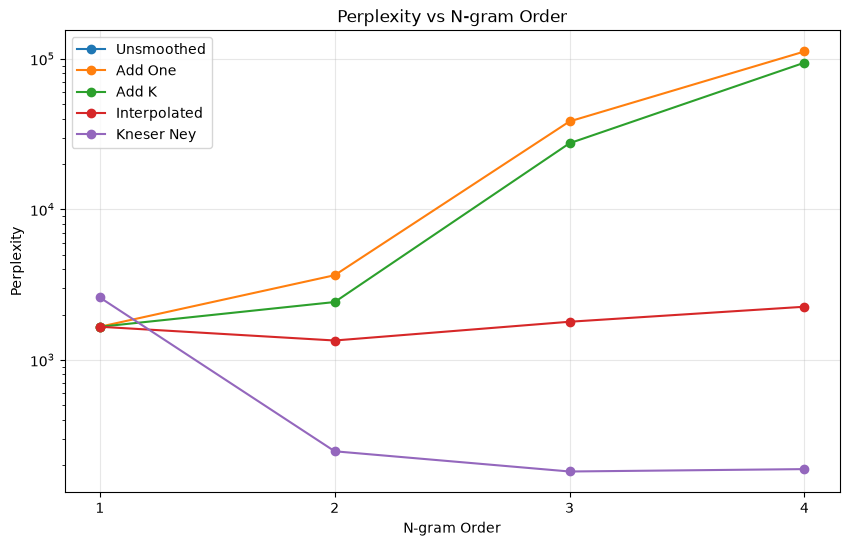

In [95]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 6))

for method in methods:
    data = results_df[
        results_df["Method"] == method
    ].sort_values("N")

    plt.plot(
        data["N"],
        data["Perplexity"],
        marker="o",
        label=method.replace("_", " ").title()
    )

plt.yscale("log")

plt.xlabel("N-gram Order")
plt.ylabel("Perplexity")
plt.title("Perplexity vs N-gram Order")
plt.xticks([1, 2, 3, 4])
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

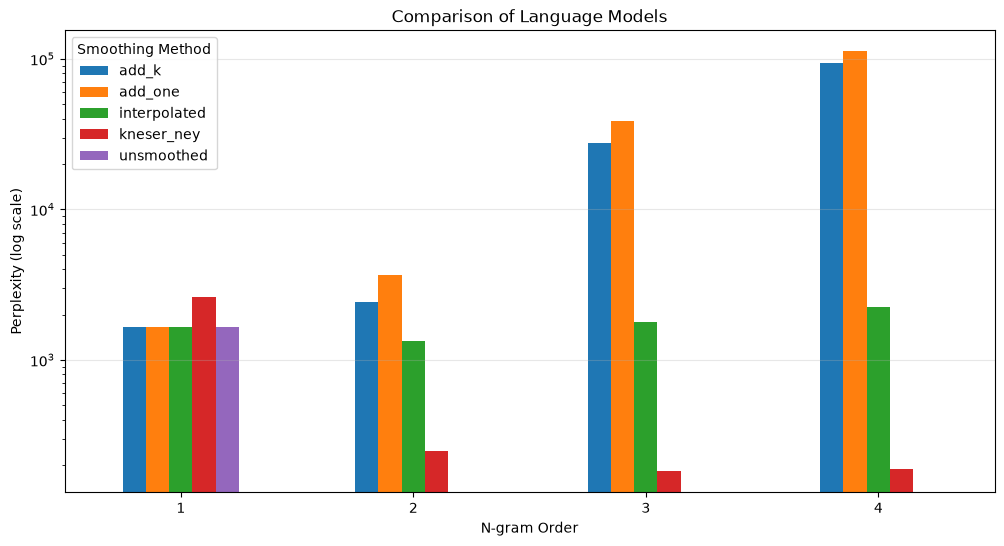

In [96]:
pivot_plot = results_df.pivot(
    index="N",
    columns="Method",
    values="Perplexity"
)

pivot_plot.plot(
    kind="bar",
    figsize=(12, 6),
    logy=True
)

plt.xlabel("N-gram Order")
plt.ylabel("Perplexity (log scale)")
plt.title("Comparison of Language Models")
plt.xticks(rotation=0)
plt.legend(title="Smoothing Method")
plt.grid(axis="y", alpha=0.3)

plt.show()

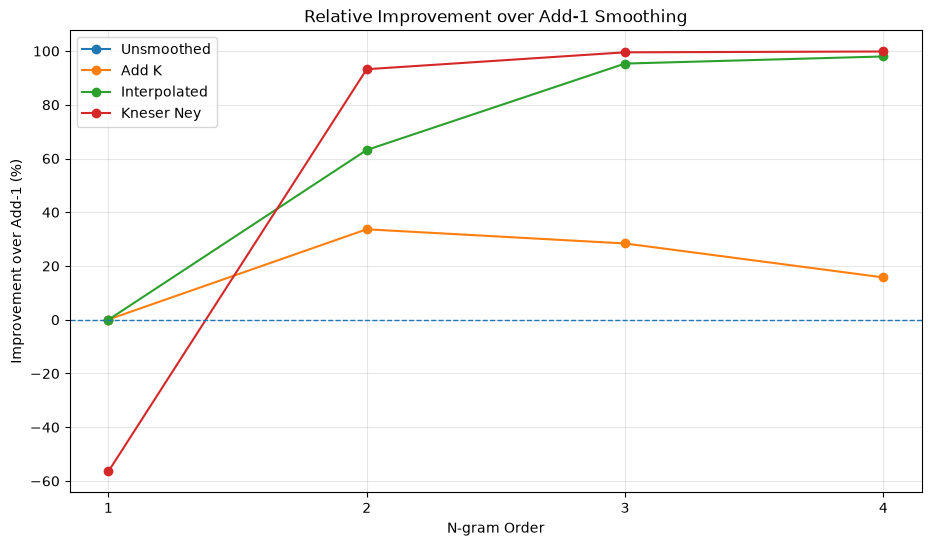

In [98]:
baseline = (
    results_df[results_df["Method"] == "add_one"]
    [["N", "Perplexity"]]
    .rename(columns={"Perplexity": "Add_1"})
)

method_comparison = results_df.merge(
    baseline,
    on="N"
)

method_comparison["Improvement_vs_Add1_%"] = (
    (method_comparison["Add_1"] -
     method_comparison["Perplexity"])
    / method_comparison["Add_1"]
    * 100
)

method_comparison[
    [
        "N",
        "Method",
        "Perplexity",
        "Improvement_vs_Add1_%"
    ]
]

improvement_plot = method_comparison[
    method_comparison["Method"] != "add_one"
].copy()

plt.figure(figsize=(11, 6))

for method in improvement_plot["Method"].unique():

    data = improvement_plot[
        improvement_plot["Method"] == method
    ].sort_values("N")

    plt.plot(
        data["N"],
        data["Improvement_vs_Add1_%"],
        marker="o",
        label=method.replace("_", " ").title()
    )

plt.axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("N-gram Order")
plt.ylabel("Improvement over Add-1 (%)")
plt.title("Relative Improvement over Add-1 Smoothing")
plt.xticks([1, 2, 3, 4])
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()